# 05b Warm start with a step size matched to the estimator

In 05 the warm start uses the paper's hyper parameters (smoothing sigma 12.5 mm, Adam learning rate 0.02 m). Adam's first steps are about one learning rate long, so a start that is already within a few millimetres is pushed away again. Here the same test spheres are rerun from the estimator's guess with sigma and learning rate set to about the estimator's lateral error (3 mm). Everything else is unchanged.

In [1]:
%run ./00_common.ipynb

C:\Users\Rey\anaconda3\envs\kolb\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


PROJECT  : C:\Users\Rey\Documents\Kolb_Radar_Project
FAKE_MODE: False
[mitsuba] Warning: Couldn't import the ipywidgets package. Installing this package is required for the system to properly log messages and print in Jupyter notebooks!


torch device: cuda
mitsuba variant: cuda_ad_rgb


Switched off Tx:  2
Switched off Rx:  10
torch 2.5.1+cu121 | device cuda
common ready


In [2]:
N_CASES = int(os.environ.get('KOLB_WARM_CASES', '6')); EPOCHS = int(os.environ.get('KOLB_WARM_EPOCHS', '30'))
SIGMA = float(os.environ.get('KOLB_ADAPT_SIGMA', '0.003')); LR = float(os.environ.get('KOLB_ADAPT_LR', '0.003'))
X, P = load_dataset(); _, _, te = split_indices(len(X))
cases = te[:N_CASES]
model = OneShotNet().to(DEVICE); model.load_state_dict(torch.load(MODELS / 'oneshot_fp32.pt', map_location=DEVICE)); model.eval()
rows = []
for k, i in enumerate(cases):
    gt = P[i]
    with torch.no_grad():
        x_pred = float(from_unit(model(torch.from_numpy(X[i:i+1].astype(np.float32)).to(DEVICE)).cpu().numpy())[0, 0])
    res = run_inverse_1d(gt, x_pred, epochs=EPOCHS, sigma=SIGMA, lr=LR)
    rows.append({'case': int(i), 'true_x_mm': float(gt[0]) * 1000, 'pred_x_mm': x_pred * 1000, 'sigma': SIGMA, 'lr': LR,
                 'warm_adapted': {kk: res[kk] for kk in ('final_err_mm', 'iters_to_tol', 'seconds')}, 'warm_adapted_hist': res['history_mm']})
    print(f"case {k+1}/{len(cases)}: true {rows[-1]['true_x_mm']:.1f} mm, predicted {rows[-1]['pred_x_mm']:.1f} mm, final {res['final_err_mm']:.2f} mm")
    save_json(rows, '05b_warm_adapted_cases.json')
hist = np.array([r['warm_adapted_hist'] for r in rows])
best = np.minimum.accumulate(hist, axis=1)
within2 = [int(np.argmax(b < 2.0)) if (b < 2.0).any() else None for b in best]
summ = {'n_cases': len(rows), 'epochs': EPOCHS, 'sigma_m': SIGMA, 'lr_m': LR,
        **{f'median_err_mm_after_{k}_iters': float(np.median(hist[:, k])) for k in (0, 5, 10, 20) if k < hist.shape[1]},
        'median_final_err_mm': float(np.median([r['warm_adapted']['final_err_mm'] for r in rows])),
        'mean_final_err_mm': float(np.mean([r['warm_adapted']['final_err_mm'] for r in rows])),
        'reached_2mm': f"{sum(x is not None for x in within2)}/{len(within2)}",
        'mean_seconds': float(np.mean([r['warm_adapted']['seconds'] for r in rows]))}
save_json(summ, '05b_warm_adapted_summary.json'); print(json.dumps(summ, indent=2))
log(f'05b warm start with adapted step: {json.dumps(summ)}')

case 1/6: true 39.8 mm, predicted 39.5 mm, final 0.04 mm
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05b_warm_adapted_cases.json


case 2/6: true -34.1 mm, predicted -32.1 mm, final 0.02 mm
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05b_warm_adapted_cases.json


case 3/6: true 107.3 mm, predicted 108.2 mm, final 0.01 mm
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05b_warm_adapted_cases.json


case 4/6: true 25.6 mm, predicted 25.3 mm, final 0.05 mm
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05b_warm_adapted_cases.json


case 5/6: true -4.3 mm, predicted -5.4 mm, final 0.00 mm
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05b_warm_adapted_cases.json


case 6/6: true -89.3 mm, predicted -91.0 mm, final 0.02 mm
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05b_warm_adapted_cases.json
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05b_warm_adapted_summary.json
{
  "n_cases": 6,
  "epochs": 30,
  "sigma_m": 0.003,
  "lr_m": 0.003,
  "median_err_mm_after_0_iters": 0.985240563750267,
  "median_err_mm_after_5_iters": 1.168966293334961,
  "median_err_mm_after_10_iters": 0.8918438106775284,
  "median_err_mm_after_20_iters": 0.5320636555552483,
  "median_final_err_mm": 0.01623108983039856,
  "mean_final_err_mm": 0.02228763575355212,
  "reached_2mm": "6/6",
  "mean_seconds": 336.0398866335551
}
2026-10-27 02:55:30  05b warm start with adapted step: {"n_cases": 6, "epochs": 30, "sigma_m": 0.003, "lr_m": 0.003, "median_err_mm_after_0_iters": 0.985240563750267, "median_err_mm_after_5_iters": 1.168966293334961, "median_err_mm_after_10_iters": 0.8918438106775284, "median_err_mm_after_20_iters": 0.5320636555552483,

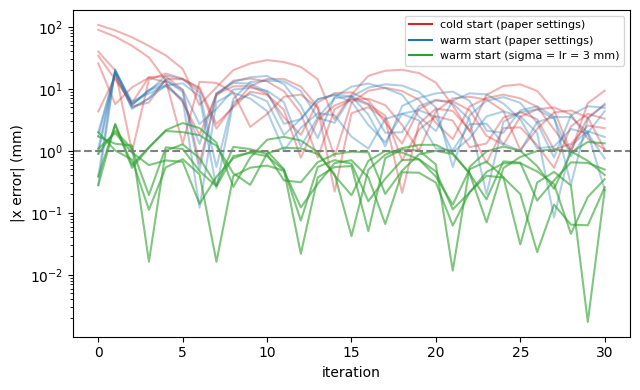

In [3]:
import matplotlib.pyplot as plt
c5 = json.load(open(RESULTS / '05_warm_start_cases.json'))
plt.figure(figsize=(6.5, 4))
for r in c5:
    plt.semilogy(r['cold_hist'], c='tab:red', alpha=.35); plt.semilogy(r['warm_hist'], c='tab:blue', alpha=.35)
for r in rows:
    plt.semilogy(r['warm_adapted_hist'], c='tab:green', alpha=.6)
plt.plot([], [], c='tab:red', label='cold start (paper settings)'); plt.plot([], [], c='tab:blue', label='warm start (paper settings)')
plt.plot([], [], c='tab:green', label=f'warm start (sigma = lr = {SIGMA*1000:.0f} mm)')
plt.axhline(1.0, ls='--', c='grey'); plt.xlabel('iteration'); plt.ylabel('|x error| (mm)'); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / '05b_three_starts.png', dpi=200); plt.show()